# 02 - Exploratory data analysis: univariate and bivariate (household level)

DRAFT code written by Claude (AI assistant) for study and verification. Fill in the Purpose / What the code does / My result fields in your own words after you have run and understood each cell.

Input: `household_table.csv` from notebook 01 (one-family households, major income earner's row). Output: tables (CSV) and figures (PNG) saved to an `EDA_outputs` folder, to be copied into the GitHub repo.

Counts and percentages are unweighted (the households in the sample) unless a column or chart says weighted (weighted by FWEIGHT, to compare with published prevalence). All nine predictors are treated as categories (income quintile, tenure, has_children and edu_household were built in notebook 01; HHSIZE is also treated as a category here), so no correlation of codes as if they were quantities is computed.

### Step 1 - Libraries, folders, and loading the table

**Purpose:**

**What the code does:**

**Learn from:** [pandas.read_csv](https://pandas.pydata.org/docs/reference/api/pandas.read_csv.html), [nullable integers](https://pandas.pydata.org/docs/user_guide/integer_na.html)

**My result:**

In [1]:
# ================= SETTINGS: the only lines to change when reproducing this work =================
# 1. Download the five Canadian Income Survey public-use files (CIS2018_PUMF.txt ... CIS2022_PUMF.txt) from Statistics Canada
#    and put them in a folder called ProjectData inside base_path. They are large files, so they are not stored on GitHub.
# 2. Google Colab with Google Drive: keep the path below, or change it to wherever you put the folder.
#    Your own computer (no Drive): replace it with a local folder, e.g. './CIND820_CapstoneProject'.
# 3. Run notebook 01, then 02. The results are written to ProcessedData and EDA_outputs inside base_path.
base_path = '/content/drive/MyDrive/CIND820_CapstoneProject'
# ===================================================================================================

import os
import textwrap                          # wraps long labels so chart axes stay readable (standard library)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt          # charts
from scipy.stats import chi2_contingency                # chi-square test of independence
from scipy.stats.contingency import association         # Cramer's V (effect size for two categorical variables)

try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    pass

input_file = f'{base_path}/ProcessedData/household_table.csv'      # made by notebook 01
missing_file = f'{base_path}/ProcessedData/missingness_by_year.csv'
outputs_dir = f'{base_path}/EDA_outputs'                           # copy this folder into the GitHub repo afterwards
os.makedirs(outputs_dir, exist_ok=True)

# Must match the predictors list in notebook 01 (remove or add names to change the analysis)
predictors = ['income_quintile', 'tenure', 'has_children', 'SEX', 'edu_household', 'IMMST', 'MAJRI', 'PROV', 'HHSIZE']
years = [2018, 2019, 2020, 2021, 2022]

# Everything except the weight is a code, so read it as a nullable integer (Int64: whole numbers that may be missing).
# This is the type check the Milestone 2 page asks for: profiling tools can treat IDs and codes as ordinary numbers.
code_cols = ['YEAR', 'PUMFID', 'FSCHHLDM', 'food_insecure'] + predictors
hh = pd.read_csv(input_file, dtype={c: 'Int64' for c in code_cols}, usecols=lambda c: c in code_cols + ['FWEIGHT'])
# FWEIGHT (the major income earner's person weight) times the 0/1 target: used below for weighted food insecurity rates
hh['weight_x_insecure'] = hh['FWEIGHT'] * hh['food_insecure']
print(hh.shape)
print(hh.dtypes)

Mounted at /content/drive
(201171, 15)
YEAR                   Int64
PUMFID                 Int64
FWEIGHT              float64
FSCHHLDM               Int64
food_insecure          Int64
income_quintile        Int64
tenure                 Int64
has_children           Int64
SEX                    Int64
edu_household          Int64
IMMST                  Int64
MAJRI                  Int64
PROV                   Int64
HHSIZE                 Int64
weight_x_insecure    Float64
dtype: object


### Step 2 - Labels from the data dictionaries (so tables show words, not only codes)

**Purpose:**

**What the code does:**

**Learn from:** The 'Answer Categories' of each variable in the data dictionaries

**My result:**

In [2]:
# Code -> label. PROV, HLEV2G, IMMST, MAJRI and FSCHHLDM are copied from the answer categories in the dictionaries
# (identical in all five years); SEX likewise. income_quintile, tenure, has_children and edu_household were defined in notebook 01.
labels = {'PROV': {10: 'Newfoundland and Labrador',
          11: 'Prince Edward Island',
          12: 'Nova Scotia',
          13: 'New Brunswick',
          24: 'Quebec',
          35: 'Ontario',
          46: 'Manitoba',
          47: 'Saskatchewan',
          48: 'Alberta',
          59: 'British Columbia'},
 'HLEV2G': {1: 'Less than high school graduation',
            2: 'Graduated high school or partial postsecondary education',
            3: 'Non-university postsecondary certificate or diploma',
            4: 'University degree or certificate',
            6: 'Valid skip',
            9: 'Not stated'},
 'IMMST': {1: 'Yes', 2: 'No', 6: 'Valid skip', 9: 'Not stated'},
 'FSCHHLDM': {0: 'Food secure',
              1: 'Marginally food insecure',
              2: 'Moderately food insecure',
              3: 'Severely food insecure'},
 'MAJRI': {1: 'No income',
           2: 'Wages and salaries',
           3: 'Self-employment income',
           4: 'Government transfers',
           5: 'Investment income',
           6: 'Private retirement pensions',
           7: 'Other income',
           96: 'Valid skip'},
 'income_quintile': {1: 'Lowest fifth',
                     2: 'Second fifth',
                     3: 'Middle fifth',
                     4: 'Fourth fifth',
                     5: 'Highest fifth'},
 'tenure': {1: 'Not owned', 2: 'Owned, with mortgage', 3: 'Owned, no mortgage'},
 'has_children': {0: 'Adults only', 1: 'At least one person under 18'},
 'edu_household': {1: 'Less than high school graduation',
                   2: 'Graduated high school or partial postsecondary education',
                   3: 'Non-university postsecondary certificate or diploma',
                   4: 'University degree or certificate'},
 'SEX': {1: 'Male', 2: 'Female'}}


def label(var, code):
    """'35 - Ontario' for coded variables; the plain number for HHSIZE."""
    if var in labels and int(code) in labels[var]:
        return f'{int(code)} - {labels[var][int(code)]}'
    return str(int(code))

def wrap(text, width=38):
    return '\n'.join(textwrap.wrap(str(text), width))

year_colors = plt.cm.viridis(np.linspace(0.1, 0.9, len(years)))   # ordered colours: darker = earlier year

def save_fig(fig, name):
    fig.savefig(f'{outputs_dir}/{name}.png', dpi=150, bbox_inches='tight')
    plt.show()
    plt.close(fig)

## 1. Target: food security status of the household

### Step 3 - Target by year (counts, percentages, binary target)

**Purpose:**

**What the code does:**

**Learn from:** [DataFrame.groupby](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.groupby.html), [numpy.average](https://numpy.org/doc/stable/reference/generated/numpy.average.html), [pandas.crosstab](https://pandas.pydata.org/docs/reference/api/pandas.crosstab.html)

**My result:**

YEAR,2018,2019,2020,2021,2022
0 - Food secure,33047,26198,44988,31976,32449
1 - Marginally food insecure,1844,1319,2201,1828,2178
2 - Moderately food insecure,2839,2033,3277,2729,3775
3 - Severely food insecure,1751,1162,1769,1482,2326
Total households,39481,30712,52235,38015,40728


YEAR,2018,2019,2020,2021,2022
0 - Food secure,83.7,85.3,86.1,84.1,79.7
1 - Marginally food insecure,4.7,4.3,4.2,4.8,5.3
2 - Moderately food insecure,7.2,6.6,6.3,7.2,9.3
3 - Severely food insecure,4.4,3.8,3.4,3.9,5.7


,households,unweighted_pct,weighted_pct
2018,39481,16.3,16.0
2019,30712,14.7,15.7
2020,52235,13.9,15.8
2021,38015,15.9,17.6
2022,40728,20.3,22.4


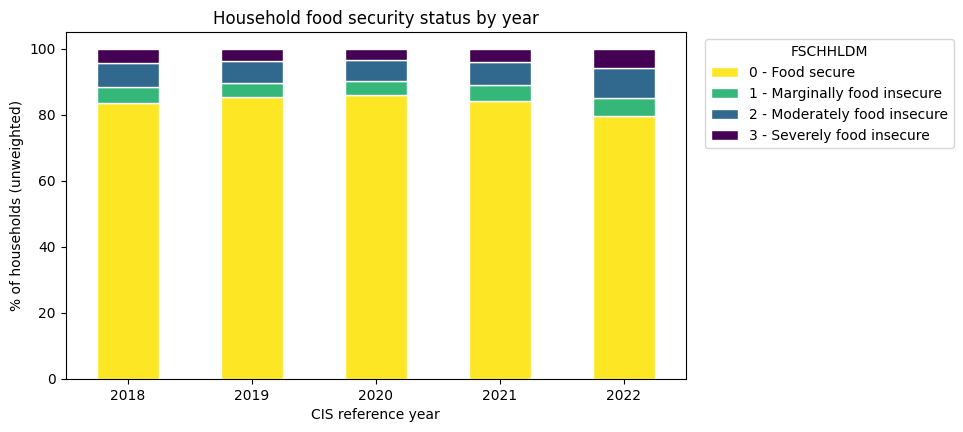

In [3]:
# --- Households in each FSCHHLDM category, by year ---
counts = pd.crosstab(hh['FSCHHLDM'], hh['YEAR'])          # rows = category, columns = year
counts.index = [label('FSCHHLDM', c) for c in counts.index]
counts.loc['Total households'] = counts.sum()
display(counts)

# --- The same as % of the year's households (unweighted) ---
share = (100 * counts.drop('Total households') / counts.loc['Total households']).round(1)
display(share)

# --- Binary target: % of households with ANY food insecurity (codes 1, 2, 3) ---
summary = pd.DataFrame({
    'households': hh.groupby('YEAR').size(),
    'unweighted_pct': (100 * hh.groupby('YEAR')['food_insecure'].mean()).round(1),    # % of households with any food insecurity
    # Weights each household by the major income earner's person weight FWEIGHT (the household weight we decided to use).
    # No bootstrap weights exist in the public file, so this is a point estimate without a design-based interval.
    'weighted_pct': pd.Series({
        y: 100 * np.average(g['food_insecure'], weights=g['FWEIGHT']) for y, g in hh.groupby('YEAR')}).round(1),
})
display(summary)
# index_label puts a name in the top-left cell of each CSV (without it that cell is empty)
counts.to_csv(f'{outputs_dir}/target_counts_by_year.csv', index_label='FSCHHLDM')
share.to_csv(f'{outputs_dir}/target_share_by_year.csv', index_label='FSCHHLDM')
summary.to_csv(f'{outputs_dir}/target_binary_by_year.csv', index_label='YEAR')

# --- Chart: shares of the four categories by year (stacked bars) ---
fig, ax = plt.subplots(figsize=(8, 4.5))
share.T.plot(kind='bar', stacked=True, ax=ax, colormap='viridis_r', edgecolor='white')
ax.set_ylabel('% of households (unweighted)')
ax.set_xlabel('CIS reference year')
ax.set_title('Household food security status by year')
ax.legend(title='FSCHHLDM', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.xticks(rotation=0)
save_fig(fig, 'target_by_year')

## 2. Missing values and special codes

### Step 4 - How much is missing, by variable and year

**Purpose:**

**What the code does:**

**Learn from:** [DataFrame.pivot](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.pivot.html), [DataFrame.loc](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.loc.html), [Series.isin](https://pandas.pydata.org/docs/reference/api/pandas.Series.isin.html)

**My result:**

In [4]:
# Valid skip (question did not apply to this person) and not stated (applied but no answer) from notebook 01,
# counted for the major income earner of each kept household, before they were turned into missing values.
# The table covers the variables read from the files (ALFST is there only as the reason it was dropped).
miss = pd.read_csv(missing_file)
miss['missing_pct'] = miss['valid_skip_pct'] + miss['not_stated_pct'] + miss['blank_pct']
miss_wide = miss.pivot(index='variable', columns='YEAR', values='missing_pct').round(2)
display(miss_wide)
miss_wide.to_csv(f'{outputs_dir}/missing_pct_by_variable_year.csv')

# Cross-check on the saved table: missing values left in each predictor, as % of households, by year
display((100 * hh[predictors].isna().groupby(hh['YEAR']).mean()).round(2).T)

# Split the missing values for three variables into valid skip (question did not apply),
# not stated (applied but no answer) and blank. Uses the `miss` table built above.
# DataFrame.loc: https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.loc.html
# Series.isin:   https://pandas.pydata.org/docs/reference/api/pandas.Series.isin.html
cols_to_show = ['YEAR', 'variable', 'valid_skip_pct', 'not_stated_pct', 'blank_pct']
display(miss.loc[miss['variable'].isin(['ALFST', 'IMMST', 'HLEV2G']), cols_to_show])

YEAR,2018,2019,2020,2021,2022
variable,,,,,
ALFST,19.00,21.63,23.56,24.37,25.29
EFAGYFMP,0.00,0.00,0.00,0.00,0.00
EFATINC,0.00,0.00,0.00,0.00,0.00
HHSIZE,0.00,0.00,0.00,0.00,0.00
HLEV2G,4.17,4.25,4.15,4.72,4.85
IMMST,1.64,3.85,4.09,4.34,5.10
MAJRI,0.00,0.00,0.00,0.00,0.00
PROV,0.00,0.00,0.00,0.00,0.00
SEX,0.00,0.00,0.00,0.00,0.00


YEAR,2018,2019,2020,2021,2022
income_quintile,0.00,0.00,0.00,0.00,0.00
tenure,0.00,0.00,0.00,0.00,0.00
has_children,0.00,0.00,0.00,0.00,0.00
SEX,0.00,0.00,0.00,0.00,0.00
edu_household,2.30,2.54,2.38,2.73,2.68
IMMST,1.64,3.85,4.09,4.34,5.10
MAJRI,0.00,0.00,0.00,0.00,0.00
PROV,0.00,0.00,0.00,0.00,0.00
HHSIZE,0.00,0.00,0.00,0.00,0.00


,YEAR,variable,valid_skip_pct,not_stated_pct,blank_pct
4,2018,HLEV2G,0.00,4.17,0.0
6,2018,IMMST,0.00,1.64,0.0
9,2018,ALFST,17.65,1.35,0.0
14,2019,HLEV2G,0.00,4.25,0.0
16,2019,IMMST,0.00,3.85,0.0
19,2019,ALFST,18.88,2.75,0.0
24,2020,HLEV2G,0.00,4.15,0.0
26,2020,IMMST,0.00,4.09,0.0
29,2020,ALFST,20.91,2.65,0.0
34,2021,HLEV2G,0.00,4.72,0.0


## 3. Univariate: one predictor at a time

### Step 5 - Distribution of each predictor, by year

**Purpose:**

**What the code does:**

**Learn from:** [pandas.crosstab](https://pandas.pydata.org/docs/reference/api/pandas.crosstab.html), [matplotlib Axes.barh](https://matplotlib.org/stable/api/_as_gen/matplotlib.axes.Axes.barh.html)

**My result:**


--- income_quintile ---


YEAR,2018,2019,2020,2021,2022
1 - Lowest fifth,19.3,18.6,18.6,19.3,19.5
2 - Second fifth,20.6,20.4,19.9,19.9,20.4
3 - Middle fifth,20.8,20.4,20.7,20.1,20.4
4 - Fourth fifth,20.2,20.7,20.8,20.7,20.2
5 - Highest fifth,19.0,19.9,20.0,20.0,19.5


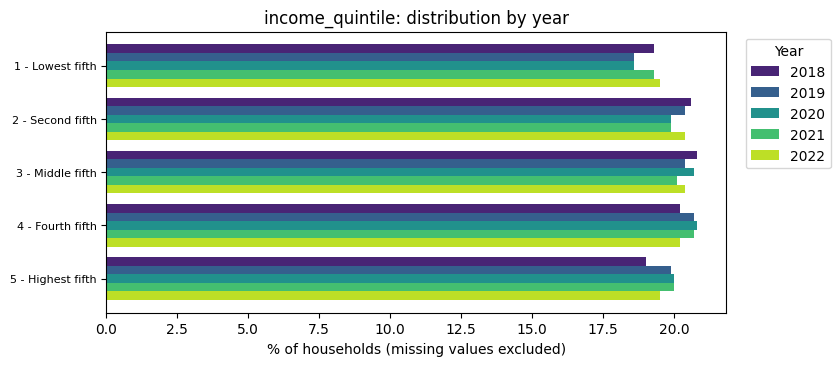


--- tenure ---


YEAR,2018,2019,2020,2021,2022
1 - Not owned,27.0,26.2,23.0,24.3,26.0
"2 - Owned, with mortgage",39.8,38.6,39.6,39.7,38.3
"3 - Owned, no mortgage",33.2,35.2,37.4,36.1,35.7


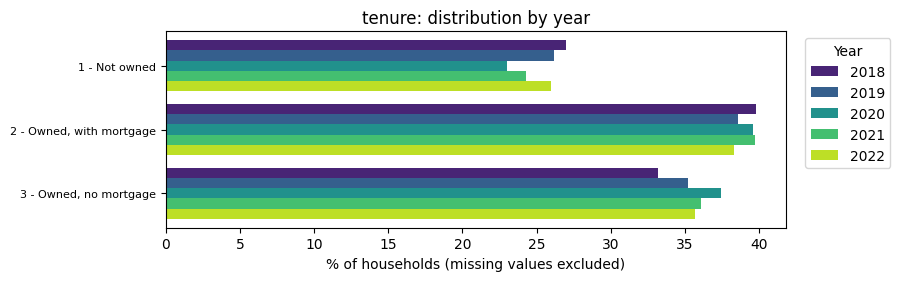


--- has_children ---


YEAR,2018,2019,2020,2021,2022
0 - Adults only,73.8,74.9,75.7,75.9,75.5
1 - At least one person under 18,26.2,25.1,24.3,24.1,24.5


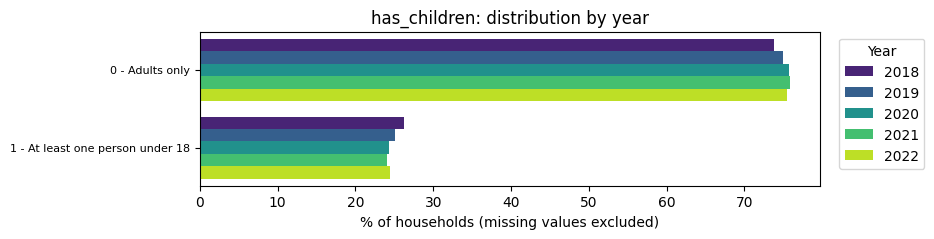


--- SEX ---


YEAR,2018,2019,2020,2021,2022
1 - Male,58.0,57.5,57.4,56.5,56.1
2 - Female,42.0,42.5,42.6,43.5,43.9


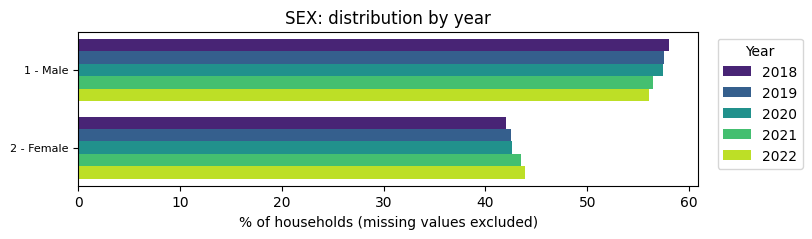


--- edu_household ---


YEAR,2018,2019,2020,2021,2022
1 - Less than high school graduation,9.6,9.3,8.7,7.8,7.7
2 - Graduated high school or partial postsecondary education,18.5,17.0,17.1,16.3,16.2
3 - Non-university postsecondary certificate or diploma,37.2,37.0,36.5,35.4,34.9
4 - University degree or certificate,34.7,36.8,37.7,40.6,41.2


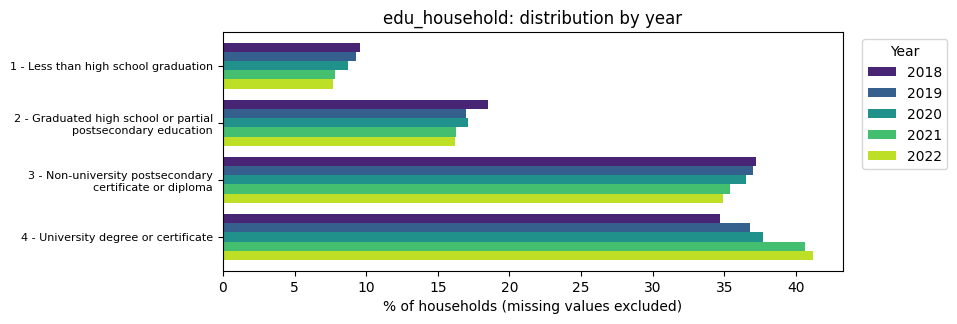


--- IMMST ---


YEAR,2018,2019,2020,2021,2022
1 - Yes,14.4,13.9,14.8,16.2,17.1
2 - No,85.6,86.1,85.2,83.8,82.9


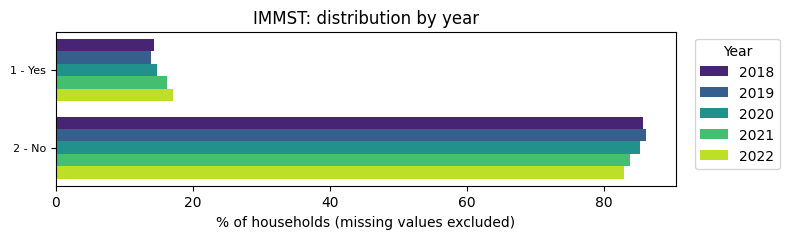


--- MAJRI ---


YEAR,2018,2019,2020,2021,2022
1 - No income,0.0,0.0,0.0,0.1,0.1
2 - Wages and salaries,57.5,57.0,53.0,55.0,56.3
3 - Self-employment income,3.8,3.5,2.7,2.8,2.9
4 - Government transfers,21.4,21.2,24.9,22.1,21.3
5 - Investment income,3.0,3.2,3.0,3.1,3.1
6 - Private retirement pensions,13.6,14.2,15.5,15.6,14.9
7 - Other income,0.9,0.9,0.9,1.3,1.3


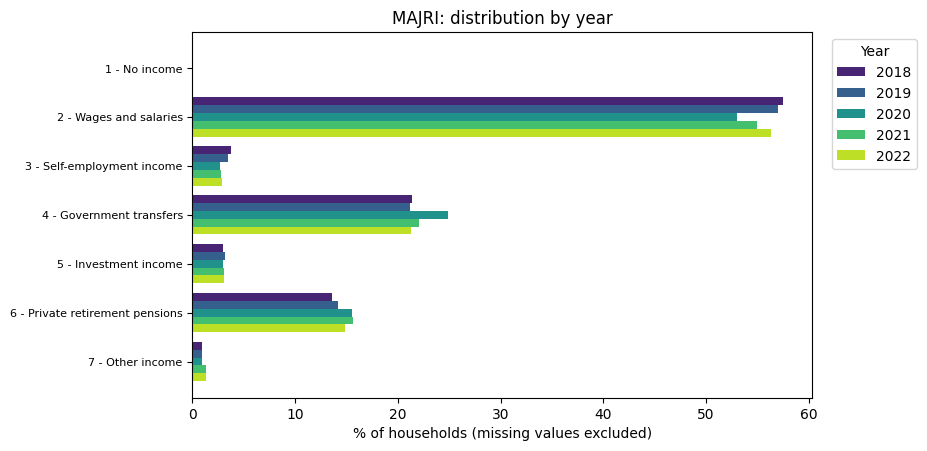


--- PROV ---


YEAR,2018,2019,2020,2021,2022
10 - Newfoundland and Labrador,3.9,3.5,3.3,3.5,4.2
11 - Prince Edward Island,2.8,2.6,2.8,2.3,2.1
12 - Nova Scotia,5.8,5.8,5.6,5.4,5.0
13 - New Brunswick,5.5,5.4,5.8,5.4,5.7
24 - Quebec,19.4,20.4,19.6,21.2,20.9
35 - Ontario,26.5,27.1,26.5,28.6,30.7
46 - Manitoba,7.9,7.7,9.3,7.9,6.9
47 - Saskatchewan,7.3,7.1,6.6,5.9,6.0
48 - Alberta,9.9,9.1,9.3,7.7,7.0
59 - British Columbia,11.1,11.3,11.2,12.1,11.4


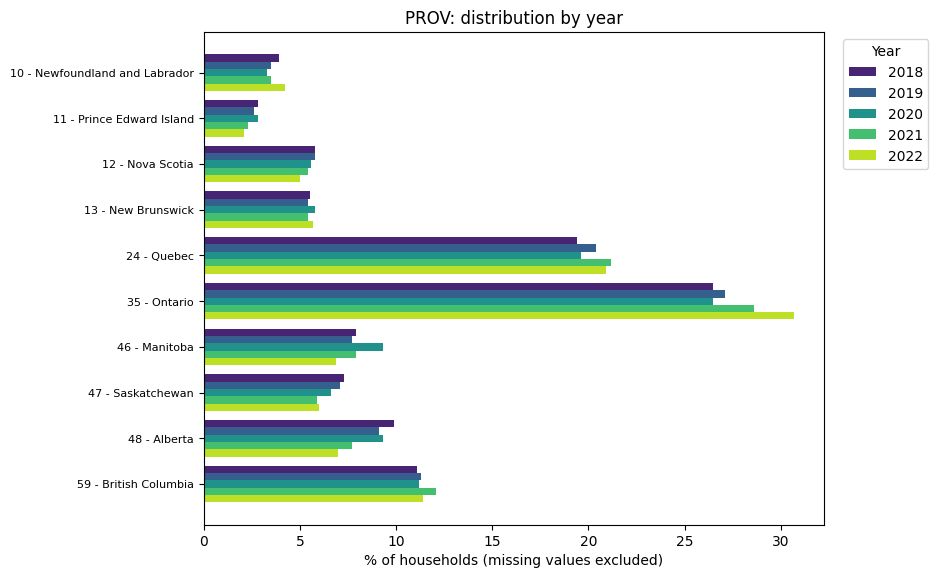


--- HHSIZE ---


YEAR,2018,2019,2020,2021,2022
1,30.4,30.5,30.2,30.7,31.1
2,37.3,38.1,38.4,37.8,37.2
3,13.5,13.1,13.2,13.2,13.2
4,12.4,11.9,12.2,12.3,12.2
5,4.4,4.3,4.2,4.1,4.4
6,1.5,1.6,1.4,1.3,1.4
7,0.5,0.5,0.5,0.5,0.6


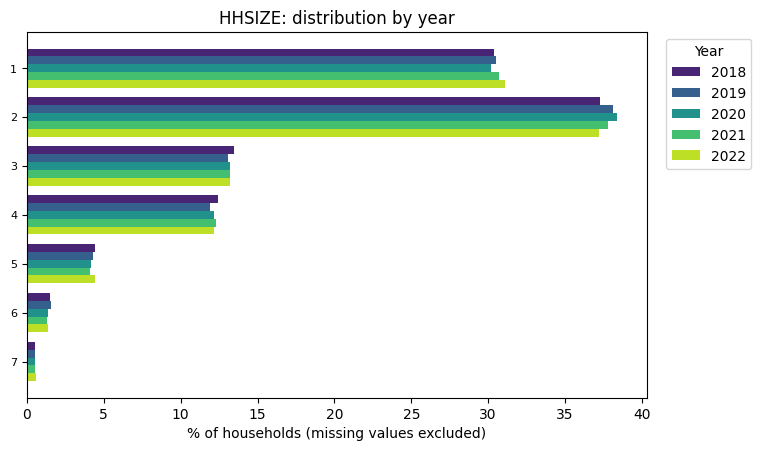

In [5]:
def univariate(var):
    """Share (%) of households in each category of `var`, for each year. Missing values are left out of the percentages."""
    tab = (100 * pd.crosstab(hh[var], hh['YEAR'], normalize='columns')).round(1)   # each year's column adds to 100
    tab.index = [label(var, c) for c in tab.index]
    tab.to_csv(f'{outputs_dir}/univariate_{var}.csv', index_label=var)
    display(tab)

    # grouped horizontal bars: one bar per year within each category
    fig, ax = plt.subplots(figsize=(8, 0.9 + 0.55 * len(tab)))
    height = 0.8 / len(years)
    for i, y in enumerate(years):
        ax.barh(np.arange(len(tab)) + i * height, tab[y], height=height, color=year_colors[i], label=str(y))
    ax.set_yticks(np.arange(len(tab)) + 0.4 - height / 2)
    ax.set_yticklabels([wrap(t) for t in tab.index], fontsize=8)
    ax.invert_yaxis()
    ax.set_xlabel('% of households (missing values excluded)')
    ax.set_title(f'{var}: distribution by year')
    ax.legend(title='Year', bbox_to_anchor=(1.02, 1), loc='upper left')
    save_fig(fig, f'univariate_{var}')

for var in predictors:
    print(f'\n--- {var} ---')
    univariate(var)

## 4. Bivariate: each predictor against the target

### Step 6 - Food insecurity rate by predictor category and year

**Purpose:**

**What the code does:**

**Learn from:** [DataFrame.groupby](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.groupby.html)

**My result:**


--- income_quintile vs food insecurity ---


,unweighted_rate_pct_2018,unweighted_rate_pct_2019,unweighted_rate_pct_2020,unweighted_rate_pct_2021,unweighted_rate_pct_2022,weighted_rate_pct_2018,weighted_rate_pct_2019,weighted_rate_pct_2020,weighted_rate_pct_2021,weighted_rate_pct_2022,n_households_2018,n_households_2019,n_households_2020,n_households_2021,n_households_2022
1 - Lowest fifth,34.3,31.6,27.4,28.4,33.5,33.4,32.6,30.5,30.9,36.8,7637,5698,9726,7351,7929
2 - Second fifth,20.6,18.7,18.6,19.7,24.0,20.0,19.5,21.0,22.6,27.4,8142,6258,10384,7547,8296
3 - Middle fifth,13.5,12.1,12.8,15.2,19.8,13.6,13.3,14.1,16.9,21.7,8212,6267,10812,7650,8324
4 - Fourth fifth,8.7,8.5,7.8,10.6,15.5,8.7,8.9,8.3,11.3,16.9,7972,6372,10845,7870,8244
5 - Highest fifth,4.5,4.0,4.0,6.0,9.0,4.4,4.1,5.1,6.4,9.2,7518,6117,10468,7597,7935


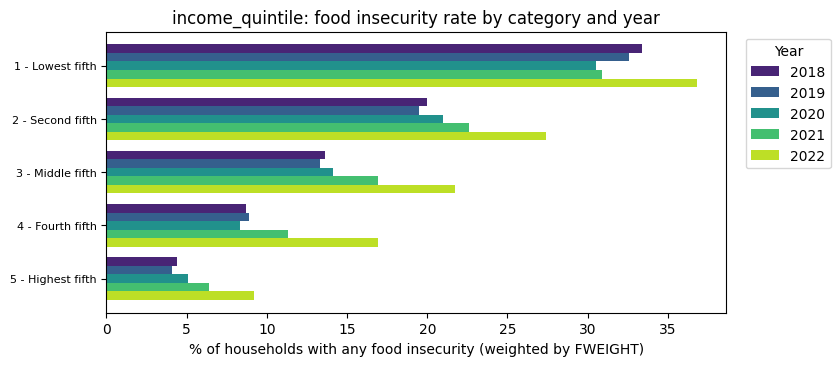


--- tenure vs food insecurity ---


,unweighted_rate_pct_2018,unweighted_rate_pct_2019,unweighted_rate_pct_2020,unweighted_rate_pct_2021,unweighted_rate_pct_2022,weighted_rate_pct_2018,weighted_rate_pct_2019,weighted_rate_pct_2020,weighted_rate_pct_2021,weighted_rate_pct_2022,n_households_2018,n_households_2019,n_households_2020,n_households_2021,n_households_2022
1 - Not owned,30.3,27.5,26.3,27.2,32.4,28.4,27.8,26.5,27.7,35.1,10671,8042,12035,9230,10571
"2 - Owned, with mortgage",14.5,13.5,13.4,15.9,21.6,13.9,13.5,13.8,16.5,21.6,15712,11870,20661,15075,15609
"3 - Owned, no mortgage",7.0,6.5,6.7,8.2,10.1,6.2,6.5,7.0,8.2,10.4,13098,10800,19539,13710,14548


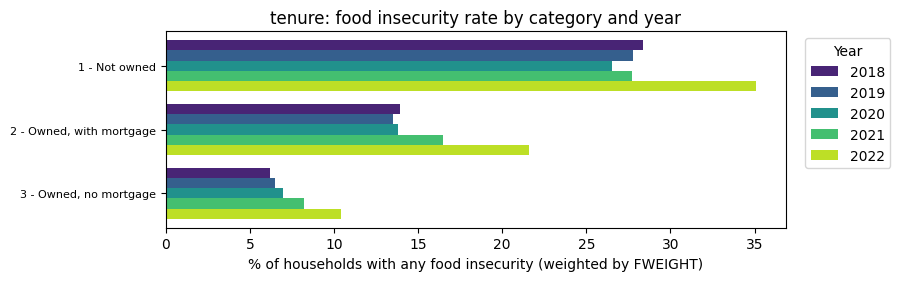


--- has_children vs food insecurity ---


,unweighted_rate_pct_2018,unweighted_rate_pct_2019,unweighted_rate_pct_2020,unweighted_rate_pct_2021,unweighted_rate_pct_2022,weighted_rate_pct_2018,weighted_rate_pct_2019,weighted_rate_pct_2020,weighted_rate_pct_2021,weighted_rate_pct_2022,n_households_2018,n_households_2019,n_households_2020,n_households_2021,n_households_2022
0 - Adults only,14.3,12.9,12.4,14.3,18.1,14.6,14.4,15.0,15.8,20.4,29155,23012,39547,28852,30738
1 - At least one person under 18,22.0,20.1,18.3,20.7,27.2,20.5,19.5,18.3,22.7,27.7,10326,7700,12688,9163,9990


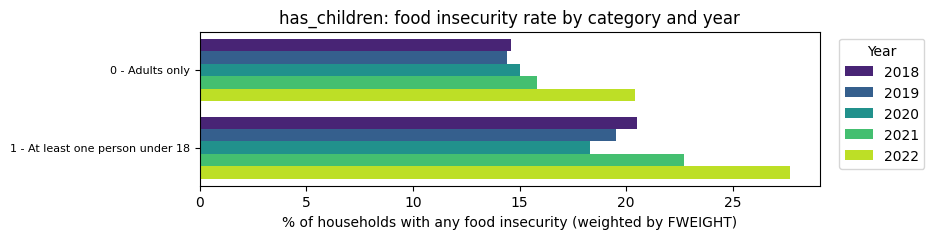


--- SEX vs food insecurity ---


,unweighted_rate_pct_2018,unweighted_rate_pct_2019,unweighted_rate_pct_2020,unweighted_rate_pct_2021,unweighted_rate_pct_2022,weighted_rate_pct_2018,weighted_rate_pct_2019,weighted_rate_pct_2020,weighted_rate_pct_2021,weighted_rate_pct_2022,n_households_2018,n_households_2019,n_households_2020,n_households_2021,n_households_2022
1 - Male,14.2,12.7,12.0,13.8,18.7,14.3,13.7,13.6,15.6,20.3,22901,17670,29994,21497,22863
2 - Female,19.2,17.4,16.4,18.6,22.4,18.5,18.3,18.8,20.3,25.3,16580,13042,22241,16518,17865


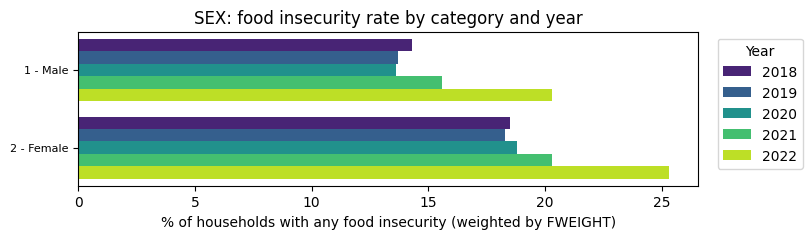


--- edu_household vs food insecurity ---


,unweighted_rate_pct_2018,unweighted_rate_pct_2019,unweighted_rate_pct_2020,unweighted_rate_pct_2021,unweighted_rate_pct_2022,weighted_rate_pct_2018,weighted_rate_pct_2019,weighted_rate_pct_2020,weighted_rate_pct_2021,weighted_rate_pct_2022,n_households_2018,n_households_2019,n_households_2020,n_households_2021,n_households_2022
1 - Less than high school graduation,21.2,17.4,16.5,19.8,20.6,20.4,18.0,17.8,21.9,21.8,3715,2777,4415,2867,3034
2 - Graduated high school or partial postsecondary education,20.8,18.9,17.7,19.0,25.2,21.0,20.5,21.1,21.4,28.1,7150,5075,8742,6021,6434
3 - Non-university postsecondary certificate or diploma,18.0,16.1,15.4,17.8,23.0,18.4,17.2,17.3,19.5,26.0,14336,11079,18601,13092,13851
4 - University degree or certificate,9.6,9.7,9.0,11.1,14.9,10.2,11.6,11.3,13.3,16.7,13370,11002,19233,14997,16316


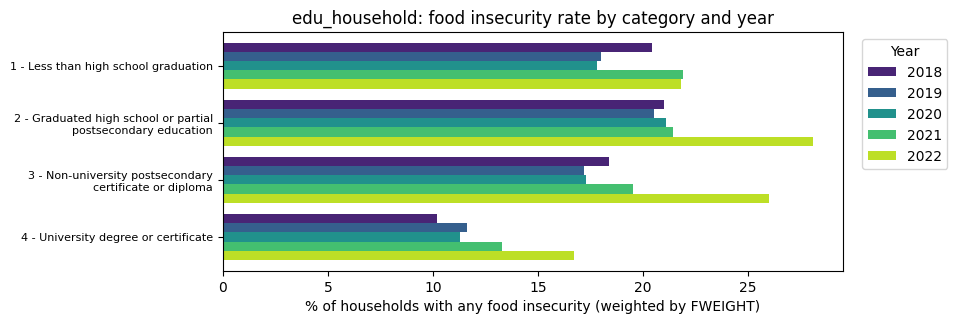


--- IMMST vs food insecurity ---


,unweighted_rate_pct_2018,unweighted_rate_pct_2019,unweighted_rate_pct_2020,unweighted_rate_pct_2021,unweighted_rate_pct_2022,weighted_rate_pct_2018,weighted_rate_pct_2019,weighted_rate_pct_2020,weighted_rate_pct_2021,weighted_rate_pct_2022,n_households_2018,n_households_2019,n_households_2020,n_households_2021,n_households_2022
1 - Yes,16.9,16.7,16.4,18.3,22.4,16.9,18.9,18.6,21.4,24.2,5605,4115,7429,5904,6619
2 - No,16.1,14.0,13.0,15.0,19.3,15.7,14.3,14.5,15.9,21.2,33227,25416,42669,30463,32032


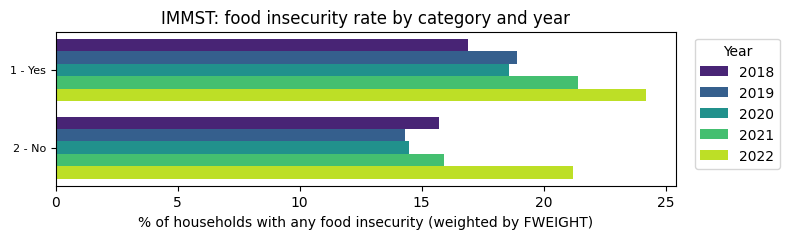


--- MAJRI vs food insecurity ---


,unweighted_rate_pct_2018,unweighted_rate_pct_2019,unweighted_rate_pct_2020,unweighted_rate_pct_2021,unweighted_rate_pct_2022,weighted_rate_pct_2018,weighted_rate_pct_2019,weighted_rate_pct_2020,weighted_rate_pct_2021,weighted_rate_pct_2022,n_households_2018,n_households_2019,n_households_2020,n_households_2021,n_households_2022
1 - No income,NaN,NaN,NaN,29.4,14.3,NaN,NaN,NaN,23.2,14.2,NaN,NaN,NaN,34.0,42.0
2 - Wages and salaries,15.5,14.2,12.8,16.1,22.3,15.0,15.1,13.4,17.0,23.5,22688.0,17499.0,27685.0,20896.0,22937.0
3 - Self-employment income,12.4,13.1,11.6,10.4,18.4,12.3,14.0,14.8,11.4,20.0,1486.0,1081.0,1420.0,1082.0,1188.0
4 - Government transfers,28.0,24.9,23.8,25.1,26.7,29.2,26.3,27.8,28.9,30.7,8435.0,6498.0,12997.0,8403.0,8694.0
5 - Investment income,7.4,6.1,5.6,5.2,8.3,8.0,7.8,8.2,5.7,10.6,1177.0,986.0,1547.0,1181.0,1248.0
6 - Private retirement pensions,4.1,4.1,4.0,5.1,6.0,3.4,4.3,4.1,5.2,6.1,5354.0,4373.0,8094.0,5935.0,6073.0
7 - Other income,17.3,10.2,8.5,16.5,26.9,15.8,13.6,14.9,19.6,31.5,341.0,275.0,492.0,484.0,546.0


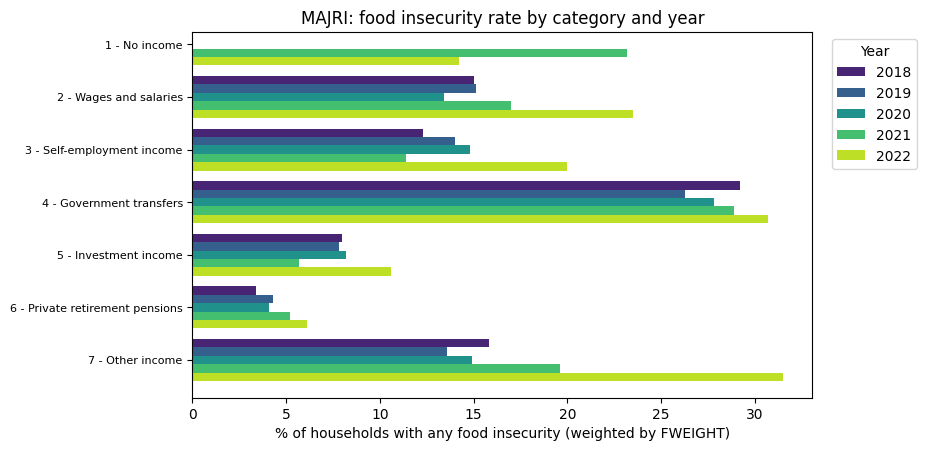


--- PROV vs food insecurity ---


,unweighted_rate_pct_2018,unweighted_rate_pct_2019,unweighted_rate_pct_2020,unweighted_rate_pct_2021,unweighted_rate_pct_2022,weighted_rate_pct_2018,weighted_rate_pct_2019,weighted_rate_pct_2020,weighted_rate_pct_2021,weighted_rate_pct_2022,n_households_2018,n_households_2019,n_households_2020,n_households_2021,n_households_2022
10 - Newfoundland and Labrador,18.6,18.1,15.8,20.7,22.4,19.1,18.4,18.3,23.2,25.4,1534,1075,1699,1327,1702
11 - Prince Edward Island,16.3,18.1,13.7,17.8,22.7,16.3,17.6,15.8,22.0,26.5,1119,806,1464,873,859
12 - Nova Scotia,20.8,17.9,15.6,19.4,25.4,21.0,17.2,18.0,21.5,27.5,2276,1768,2945,2063,2037
13 - New Brunswick,17.7,14.5,16.0,19.8,22.5,18.2,16.2,18.7,22.6,25.2,2183,1652,3012,2036,2325
24 - Quebec,12.7,10.9,10.8,11.8,13.5,13.3,11.5,13.0,13.6,16.1,7664,6274,10232,8061,8517
35 - Ontario,15.6,14.8,13.2,15.5,20.9,16.2,17.2,16.0,18.5,24.2,10453,8321,13860,10868,12505
46 - Manitoba,17.4,16.2,15.6,17.0,23.3,18.2,17.3,17.9,18.8,26.0,3101,2364,4860,3010,2825
47 - Saskatchewan,16.7,14.7,15.5,17.1,23.5,16.7,16.7,18.3,20.5,26.8,2868,2188,3443,2259,2463
48 - Alberta,19.8,16.8,17.7,20.2,25.5,19.6,17.7,20.2,22.1,27.4,3907,2805,4857,2926,2870
59 - British Columbia,16.2,15.1,12.9,14.7,20.0,15.4,16.1,14.9,16.0,21.1,4376,3459,5863,4592,4625


In [ ]:
def bivariate(var):
    """% of households with any food insecurity within each category of `var`, for each year.
    Two versions: unweighted (the households in the file) and weighted by FWEIGHT (comparable with published prevalence)."""
    g = hh.groupby([var, 'YEAR'])                     # one group per category and year; missing values are left out
    # .astype(float): a category that does not exist in some years becomes NaN, which the chart can skip;
    # pandas' own missing marker (<NA>) would make matplotlib fail.
    rate = (100 * g['food_insecure'].mean()).unstack('YEAR').astype(float).round(1)               # unweighted
    # Weighted rate = total weight of the food-insecure households / total weight of all households in the group
    rate_w = (100 * g['weight_x_insecure'].sum() / g['FWEIGHT'].sum()).unstack('YEAR').astype(float).round(1)
    n = g.size().unstack('YEAR')                                                                  # households behind each rate
    out = pd.concat({'unweighted_rate_pct': rate, 'weighted_rate_pct': rate_w, 'n_households': n}, axis=1)
    out.columns = [f'{stat}_{y}' for stat, y in out.columns]                                      # one flat header row
    out.index = [label(var, c) for c in out.index]
    out.to_csv(f'{outputs_dir}/bivariate_{var}.csv', index_label=var)
    display(out)

    # chart: the weighted rate (the population view, comparable with prevalence studies)
    fig, ax = plt.subplots(figsize=(8, 0.9 + 0.55 * len(rate_w)))
    height = 0.8 / len(years)
    for i, y in enumerate(years):
        ax.barh(np.arange(len(rate_w)) + i * height, rate_w[y], height=height, color=year_colors[i], label=str(y))
    ax.set_yticks(np.arange(len(rate_w)) + 0.4 - height / 2)
    ax.set_yticklabels([wrap(label(var, c)) for c in rate_w.index], fontsize=8)
    ax.invert_yaxis()
    ax.set_xlabel('% of households with any food insecurity (weighted by FWEIGHT)')
    ax.set_title(f'{var}: food insecurity rate by category and year')
    ax.legend(title='Year', bbox_to_anchor=(1.02, 1), loc='upper left')
    save_fig(fig, f'bivariate_{var}')

for var in predictors:
    print(f'\n--- {var} vs food insecurity ---')
    bivariate(var)

### Step 7 - How strong is each relationship, and does it change by year?

**Purpose:**

**What the code does:**

**Learn from:** [scipy chi2_contingency](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.chi2_contingency.html), [scipy association (Cramer's V)](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.contingency.association.html)

**My result:**

In [ ]:
# For every predictor and year: chi-square test of independence and Cramer's V (0 = no association, 1 = perfect).
# Caution: these tests are unweighted and ignore the survey design. With tens of thousands of households almost every
# p-value is tiny, so read Cramer's V (the size of the association), not the p-value.
rows = []
for var in predictors:
    for y in years:
        sub = hh[hh['YEAR'] == y]
        tab = pd.crosstab(sub[var], sub['food_insecure'])         # counts; missing values are left out automatically
        try:
            chi2, p, dof, _ = chi2_contingency(tab)
            v = association(tab.values, method='cramer')
        except ValueError:                                         # e.g. only one category present in that year
            chi2, p, dof, v = np.nan, np.nan, np.nan, np.nan
        rows.append({'variable': var, 'YEAR': y, 'households_used': int(tab.values.sum()),
                     'chi2': round(chi2, 1), 'dof': dof, 'p_value': p, 'cramers_v': round(v, 3)})
tests = pd.DataFrame(rows)
tests.to_csv(f'{outputs_dir}/bivariate_tests.csv', index=False)

v_table = tests.pivot(index='variable', columns='YEAR', values='cramers_v')
display(v_table)
v_table.to_csv(f'{outputs_dir}/cramers_v_by_variable_year.csv')

# Chart: Cramer's V by year, one line per predictor (flat lines = a relationship of similar strength in every year)
fig, ax = plt.subplots(figsize=(8, 4.5))
for var in predictors:
    ax.plot(years, v_table.loc[var], marker='o', label=var)
ax.set_xticks(years)
ax.set_xlabel('CIS reference year')
ax.set_ylabel("Cramer's V with food insecurity")
ax.set_title('Strength of association with food insecurity, by year')
ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
save_fig(fig, 'cramers_v_by_year')

## 5. Relationships between predictors (training years 2018-2019)

### Step 8 - Which predictors overlap with each other?

**Purpose:**

**What the code does:**

**Learn from:** [scipy association (Cramer's V)](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.contingency.association.html), [matplotlib imshow](https://matplotlib.org/stable/api/_as_gen/matplotlib.axes.Axes.imshow.html)

**My result:**

In [ ]:
# Cramer's V between every pair of predictors, using the training years only (2018 and 2019).
train = hh[hh['YEAR'].isin([2018, 2019])]
pair = pd.DataFrame(np.nan, index=predictors, columns=predictors)
for a in predictors:
    for b in predictors:
        if a == b:
            pair.loc[a, b] = 1.0
        else:
            try:
                pair.loc[a, b] = association(pd.crosstab(train[a], train[b]).values, method='cramer')
            except ValueError:
                pass
pair = pair.round(2)
display(pair)
pair.to_csv(f'{outputs_dir}/predictor_association_2018_2019.csv', index_label='predictor')

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(pair.values.astype(float), vmin=0, vmax=1, cmap='viridis_r')
ax.set_xticks(range(len(predictors)))
ax.set_xticklabels(predictors, rotation=45, ha='right')
ax.set_yticks(range(len(predictors)))
ax.set_yticklabels(predictors)
for i in range(len(predictors)):
    for j in range(len(predictors)):
        ax.text(j, i, f'{pair.values[i, j]:.2f}', ha='center', va='center', fontsize=7,
                color='white' if pair.values[i, j] > 0.5 else 'black')
fig.colorbar(im, ax=ax, label="Cramer's V")
ax.set_title("Association between predictors, CIS 2018-2019")
save_fig(fig, 'predictor_association_2018_2019')

print('Files saved in', outputs_dir)
print(sorted(os.listdir(outputs_dir)))